Sri Lankan Paddy Yield Prediction with Ensemble Learning
### Bagging vs Boosting vs Stacking vs a Hybrid (Random Forest + ANN)

**Story.** Rice is Sri Lanka's staple food and paddy farming supports close to two million rural families. Yields swing with the season (Maha vs Yala), the district's irrigation, droughts and floods, and policy. In 2021 the overnight ban on chemical fertiliser cut the Maha harvest by about a third. This notebook asks: **can ensemble models predict a district's paddy yield (kg/ha) for a coming season, and which districts and seasons do best?**

**Data.** District by season paddy statistics, 1978 to 2025: sown extent, harvested extent and average yield, split by major irrigation, minor irrigation and rainfed. Source: Department of Census and Statistics (DCS) and Central Bank of Sri Lanka (CBSL), compiled by Macro Lab ("Agriculture and fisheries: Paddy"). Monthly Samba paddy prices (CBSL) are used for the economic view.

Keep this notebook in the same folder as `paddy_models.py`, `paddy-a (1).csv` (raw) and `samba_paddy_price.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import paddy_models as pm

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 110
print("xgboost:", pm.HAS_XGB, "| lightgbm:", pm.HAS_LGBM, "| catboost:", pm.HAS_CAT)

xgboost: False | lightgbm: False | catboost: False


## 1. Data processing
The raw export is *wide*: one column per district x season x irrigation type x variable (850 columns). `clean_raw` reshapes it into one row per **district, season, year**, merges the two spellings of Kilinochchi, and keeps only the 25 administrative districts.

In [2]:
df = pm.clean_raw("paddy-a (1).csv")
df.to_csv("paddy_clean.csv", index=False)
print(df.shape, "| districts:", df["district"].nunique(), "| years:", df["year"].min(), "-", df["year"].max())
display(df.head())
display(df.describe().T.round(1))

(2240, 10) | districts: 25 | years: 1978 - 2025


var,district,season,year,sown_ha,sown_major_ha,sown_minor_ha,sown_rainfed_ha,harvested_ha,yield_kg_ha,production_mt
0,AMPARA,Maha,1978,44037.0,NaN,NaN,NaN,41779.0,3124.0,130517.596
1,AMPARA,Maha,1979,41056.0,NaN,NaN,NaN,40609.0,3597.0,146070.573
2,AMPARA,Yala,1979,28703.0,NaN,NaN,NaN,27375.0,3349.0,91678.875
3,AMPARA,Maha,1980,48835.0,NaN,NaN,NaN,48638.0,4253.0,206857.414
4,AMPARA,Yala,1980,29414.0,NaN,NaN,NaN,28805.0,4073.0,117322.765


,count,mean,std,min,25%,50%,75%,max
var,,,,,,,,
year,2240.0,2001.9,13.8,1978.0,1990.0,2002.0,2014.0,2025.0
sown_ha,2240.0,19546.7,19356.9,12.0,7118.0,13344.0,21938.2,127517.0
sown_major_ha,1792.0,10896.2,14802.0,0.0,1587.0,4496.0,12605.5,66727.0
sown_minor_ha,1946.0,4921.5,7288.1,0.0,1210.2,2799.0,5563.5,53536.0
sown_rainfed_ha,1800.0,5845.3,6989.9,0.0,790.8,3401.0,8370.2,40822.0
harvested_ha,2240.0,18636.6,18734.7,11.0,6638.0,12745.5,20478.0,127203.0
yield_kg_ha,2240.0,3541.2,844.1,1153.0,2936.8,3501.5,4097.2,6622.0
production_mt,2240.0,71491.8,83902.6,28.8,21993.8,42050.7,80319.6,659560.3


In [3]:
print("Missing values per column:")
print(df.isna().sum())
print("\nRecords per district (northern districts have gaps during the civil war years):")
print(df.groupby("district").size().sort_values().head(6))

Missing values per column:
var
district             0
season               0
year                 0
sown_ha              0
sown_major_ha      448
sown_minor_ha      294
sown_rainfed_ha    440
harvested_ha         0
yield_kg_ha          0
production_mt        0
dtype: int64

Records per district (northern districts have gaps during the civil war years):
district
KILINOCHCHI    36
JAFFNA         50
VAVUNIYA       87
MANNAR         88
MULLATIVU      88
TRINCOMALEE    89
dtype: int64


## 2. Exploratory analysis

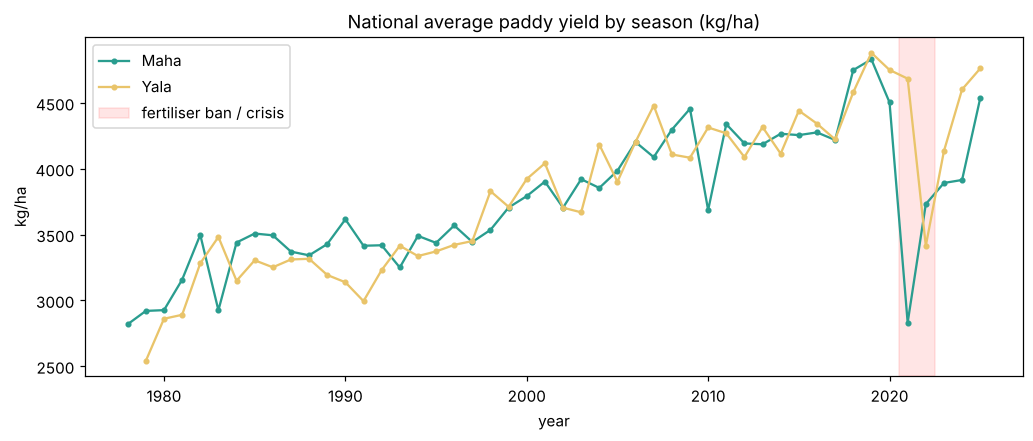

Maha 2020/21 -> 2021/22 change: -37.1%


In [4]:
nat = (df.assign(prod=df["yield_kg_ha"] * df["harvested_ha"]).groupby(["year", "season"])
         .apply(lambda g: g["prod"].sum() / g["harvested_ha"].sum()).unstack())
ax = nat.plot(figsize=(11, 4), marker="o", ms=3, color={"Maha": "#2a9d8f", "Yala": "#e9c46a"})
ax.axvspan(2020.5, 2022.5, color="red", alpha=0.1, label="fertiliser ban / crisis")
ax.set_title("National average paddy yield by season (kg/ha)"); ax.set_ylabel("kg/ha"); ax.legend(); plt.show()
print("Maha 2020/21 -> 2021/22 change: {:.1f}%".format((nat.loc[2021, "Maha"] / nat.loc[2020, "Maha"] - 1) * 100))

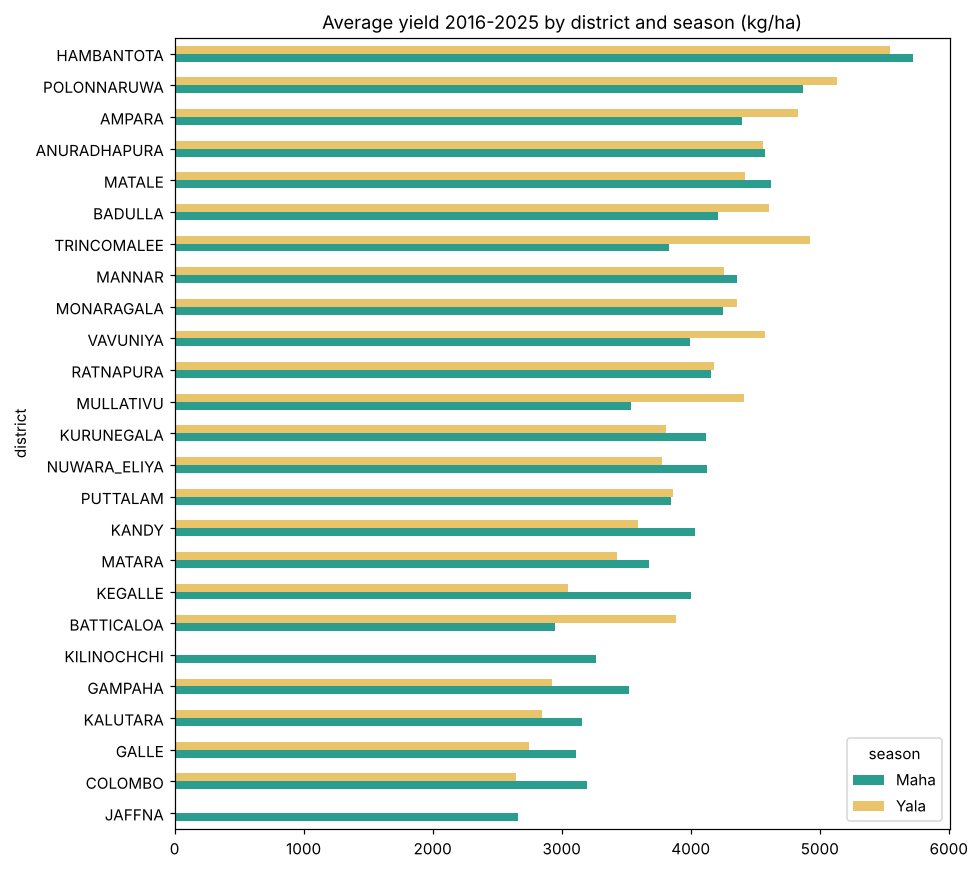

Season averages 2016-2025:
season
Maha    3928.0
Yala    4017.0
Name: yield_kg_ha, dtype: float64


In [5]:
recent = df[df["year"] >= 2016]
rank = recent.pivot_table(index="district", columns="season", values="yield_kg_ha", aggfunc="mean")
rank["mean"] = rank.mean(axis=1); rank = rank.sort_values("mean")
rank[["Maha", "Yala"]].plot.barh(figsize=(9, 8), color=["#2a9d8f", "#e9c46a"],
                                 title="Average yield 2016-2025 by district and season (kg/ha)")
plt.tight_layout(); plt.show()
print("Season averages 2016-2025:"); print(recent.groupby("season")["yield_kg_ha"].mean().round(0))

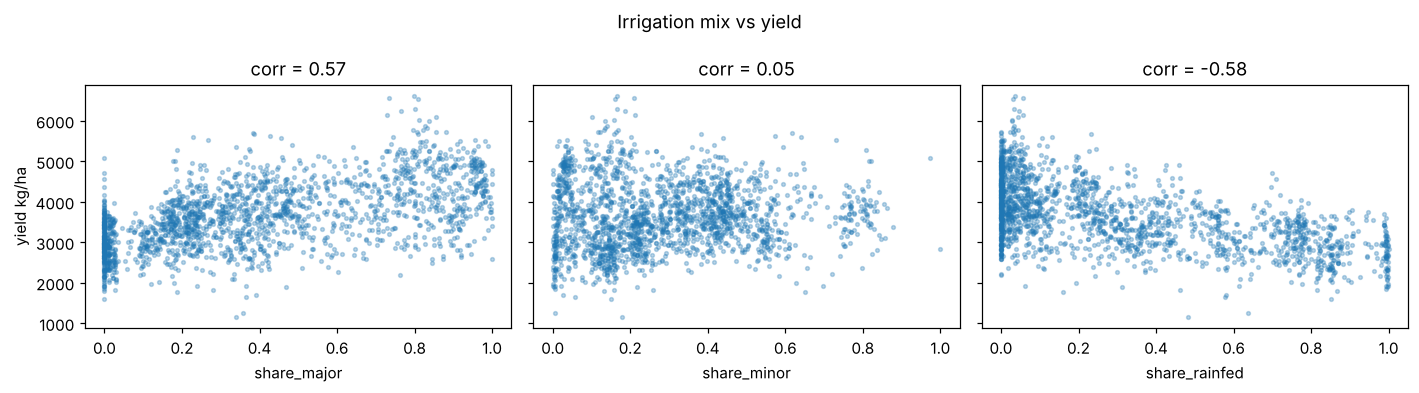

In [6]:
Xe = pm.make_features(df)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for a, c in zip(ax, ["share_major", "share_minor", "share_rainfed"]):
    a.scatter(Xe[c], Xe["target"], s=6, alpha=0.3); a.set_xlabel(c)
    a.set_title(f"corr = {Xe[[c, 'target']].corr().iloc[0, 1]:.2f}")
ax[0].set_ylabel("yield kg/ha"); plt.suptitle("Irrigation mix vs yield"); plt.tight_layout(); plt.show()

## 3. Features and time-ordered split
Every feature is known **when the crop is sown**, so this is a genuine forecast:
- district (one-hot), season (Maha = 1), year (trend)
- sown area (log) and its change vs last year, share of major / minor irrigation and rainfed land
- yield of the previous season, same season 1 and 2 years ago, 3-year average, and the national yield of the previous season

**Split:** train on 1978-2017, test on 2018-2025 (no shuffling, so no future information leaks into training). The test period deliberately includes the 2021/22 fertiliser-ban crash.

In [7]:
X = pm.make_features(df)
TRAIN_END = 2017
feats = pm.feature_columns(X)
print("usable rows:", len(X), "| features:", len(feats))
print([f for f in feats if not f.startswith("dist_")], "+ 25 district dummies")
X[["district", "season", "year"] + feats[:12] + ["target"]].tail()

usable rows: 1883 | features: 36
['year', 'is_maha', 'log_sown', 'sown_change', 'share_major', 'share_minor', 'share_rainfed', 'yield_prev_season', 'yield_lag1_same', 'yield_lag2_same', 'yield_roll3_same', 'nat_yield_prev_season'] + 25 district dummies


,district,season,year,year,is_maha,log_sown,sown_change,share_major,share_minor,share_rainfed,yield_prev_season,yield_lag1_same,yield_lag2_same,yield_roll3_same,nat_yield_prev_season,target
1878,VAVUNIYA,Maha,2023,2023,1,10.061004,-0.003872,0.202289,0.612165,0.185546,4071.000000,2861.0,2373.0,3162.333333,4134.571175,3878.000000
1879,VAVUNIYA,Yala,2024,2024,0,8.615408,-0.032790,0.544235,0.455765,0.000000,3878.000000,4071.0,4368.0,4692.333333,3892.356437,4175.000000
1880,VAVUNIYA,Maha,2024,2024,1,10.054920,-0.006065,0.204297,0.614912,0.180791,4175.000000,3878.0,2861.0,3037.333333,4603.059679,3627.000000
1881,VAVUNIYA,Yala,2025,2025,0,9.020899,0.500038,0.436222,0.563778,0.000000,3627.000000,4175.0,4071.0,4204.666667,3915.060094,4091.644415
1882,VAVUNIYA,Maha,2025,2025,1,10.056294,0.001375,0.210969,0.607716,0.181315,4091.644415,3627.0,3878.0,3455.333333,4762.125744,3857.000000


## 4. Models
| Family | Model | Idea |
|---|---|---|
| Baseline | Same season last year, 3-year average | What a farmer would guess |
| **Bagging** | Bagged decision trees, Random Forest | Many deep trees on bootstrap samples, averaged: lowers variance |
| **Boosting** | sklearn Gradient Boosting, XGBoost, LightGBM, CatBoost | Shallow trees added one after another, each fixing the last one's errors: lowers bias |
| Neural net | MLP (64-32) | Smooth non-linear function of standardised inputs |
| **Stacking** | RF + LightGBM + ANN + Ridge -> Ridge meta-learner | Learns how much to trust each model from out-of-fold predictions |
| **Hybrid** | RF + ANN residual model | RF predicts; an ANN trained on RF's out-of-fold residuals corrects it |

In [8]:
res = pm.run_experiment(X, train_end=TRAIN_END)
print("train rows:", res["n_train"], "| test rows:", res["n_test"])
for n in res["notes"]: print("NOTE:", n)
table = res["table"].sort_values("RMSE (kg/ha)")
display(table.round(3))
table.to_csv("results.csv"); res["importances"].to_csv("feature_importances.csv")

train rows: 1515 | test rows: 368


,RMSE (kg/ha),MAE (kg/ha),MAPE (%),R2,RMSE excl. 2021-22 crisis
model,,,,,
LightGBM,633.050,468.934,12.767,0.550,508.525
CatBoost,636.539,471.264,12.845,0.545,514.538
Stacking (RF + Boosting + ANN -> Ridge),640.188,468.666,13.013,0.540,488.182
XGBoost,643.591,479.405,12.938,0.535,534.269
Gradient Boosting (sklearn),645.857,483.770,13.054,0.531,529.840
ANN (MLP),652.848,484.573,13.593,0.521,496.103
Hybrid (RF + ANN residual),656.081,488.281,13.472,0.517,504.006
Random Forest,661.475,494.012,13.538,0.509,513.472
Bagging (decision trees),671.433,500.353,13.704,0.494,518.153


## 5. Performance comparison

,family,RMSE (kg/ha),MAE (kg/ha),MAPE (%),R2,RMSE excl. 2021-22 crisis,RMSE better than naive (%)
model,,,,,,,
LightGBM,Boosting,633.05,468.93,12.77,0.55,508.53,18.22
CatBoost,Boosting,636.54,471.26,12.85,0.54,514.54,17.77
Stacking (RF + Boosting + ANN -> Ridge),Stacking,640.19,468.67,13.01,0.54,488.18,17.30
XGBoost,Boosting,643.59,479.40,12.94,0.53,534.27,16.86
Gradient Boosting (sklearn),Boosting,645.86,483.77,13.05,0.53,529.84,16.57
ANN (MLP),Neural net,652.85,484.57,13.59,0.52,496.10,15.67
Hybrid (RF + ANN residual),Hybrid,656.08,488.28,13.47,0.52,504.01,15.25
Random Forest,Bagging,661.48,494.01,13.54,0.51,513.47,14.55
Bagging (decision trees),Bagging,671.43,500.35,13.70,0.49,518.15,13.26


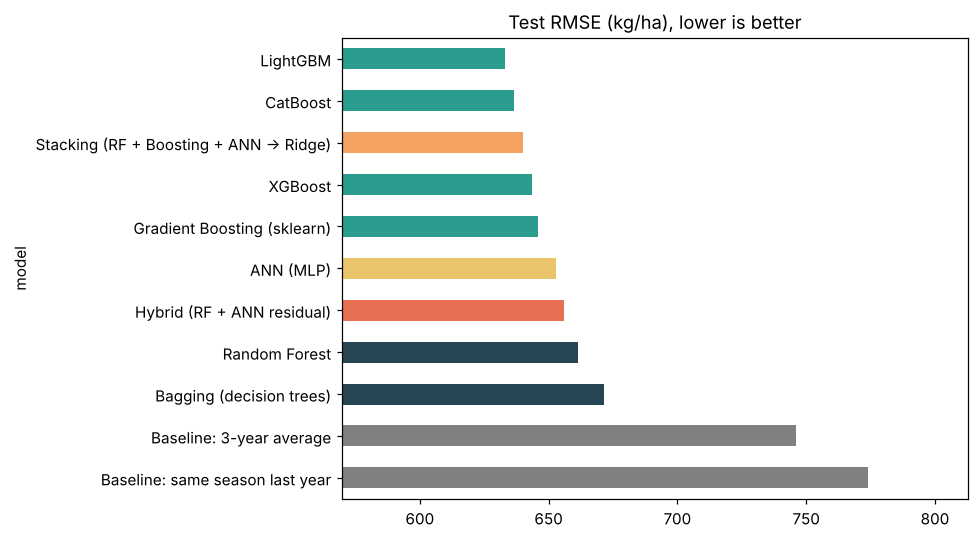

Best per family:


,idxmin,min
family,,
Bagging,Random Forest,661.5
Baseline,Baseline: 3-year average,745.9
Boosting,LightGBM,633.0
Hybrid,Hybrid (RF + ANN residual),656.1
Neural net,ANN (MLP),652.8
Stacking,Stacking (RF + Boosting + ANN -> Ridge),640.2


In [9]:
base = table.loc["Baseline: same season last year", "RMSE (kg/ha)"]
summary = table.copy()
summary["RMSE better than naive (%)"] = (1 - summary["RMSE (kg/ha)"] / base) * 100
fam = lambda m: ("Stacking" if "Stacking" in m else "Hybrid" if "Hybrid" in m else "Baseline" if "Baseline" in m
                 else "Bagging" if ("Bagging" in m or "Forest" in m) else "Neural net" if "ANN" in m else "Boosting")
summary.insert(0, "family", [fam(m) for m in summary.index])
display(summary.round(2))
colors = {"Baseline": "grey", "Bagging": "#264653", "Boosting": "#2a9d8f", "Neural net": "#e9c46a",
          "Stacking": "#f4a261", "Hybrid": "#e76f51"}
s = summary.sort_values("RMSE (kg/ha)", ascending=False)
s["RMSE (kg/ha)"].plot.barh(figsize=(9, 5), color=[colors[f] for f in s["family"]],
                            title="Test RMSE (kg/ha), lower is better")
plt.xlim(s["RMSE (kg/ha)"].min() * 0.9, None); plt.tight_layout(); plt.show()
print("Best per family:"); display(summary.groupby("family")["RMSE (kg/ha)"].agg(["idxmin", "min"]).round(1))

### 5.1 Actual vs predicted, per test season (average over districts)

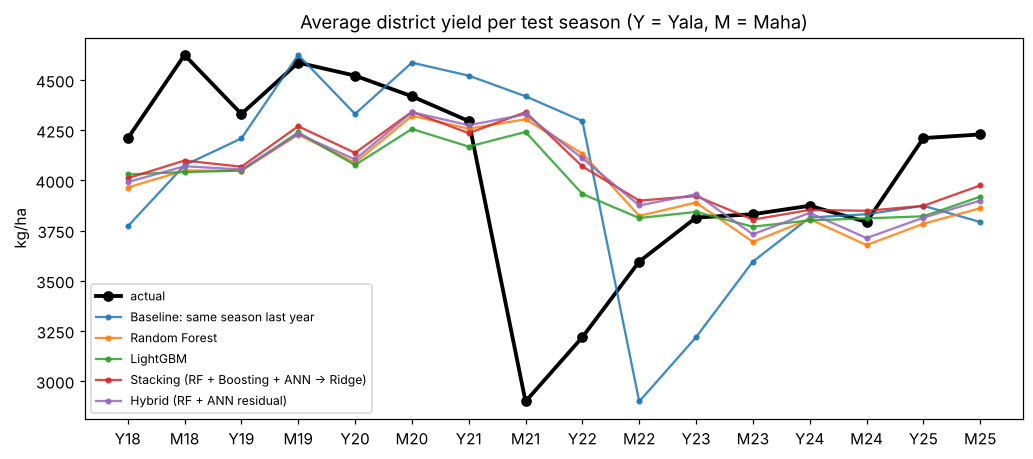

In [10]:
t = res["test"]
models = [c for c in t.columns if c not in ("district", "season", "year", "sown_ha", "harvested_ha", "target")]
g = t.groupby(["year", "season"])[["target"] + models].mean().sort_index(level=[0, 1], ascending=[True, False])
lbl = [f"{s[0]}{y % 100:02d}" for y, s in g.index]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(lbl, g["target"], "k-o", lw=2.5, label="actual")
for m in ["Baseline: same season last year", "Random Forest", "LightGBM",
          "Stacking (RF + Boosting + ANN -> Ridge)", "Hybrid (RF + ANN residual)"]:
    ax.plot(lbl, g[m], marker=".", label=m, alpha=0.85)
ax.set_title("Average district yield per test season (Y = Yala, M = Maha)"); ax.set_ylabel("kg/ha"); ax.legend(fontsize=8)
plt.show()

### 5.2 Where are the errors? By season and by district

Best model: LightGBM


season,Maha,Yala
year,,
2018,603.0,292.0
2019,428.0,512.0
2020,367.0,490.0
2021,1342.0,451.0
2022,267.0,736.0
2023,235.0,269.0
2024,285.0,421.0
2025,380.0,422.0


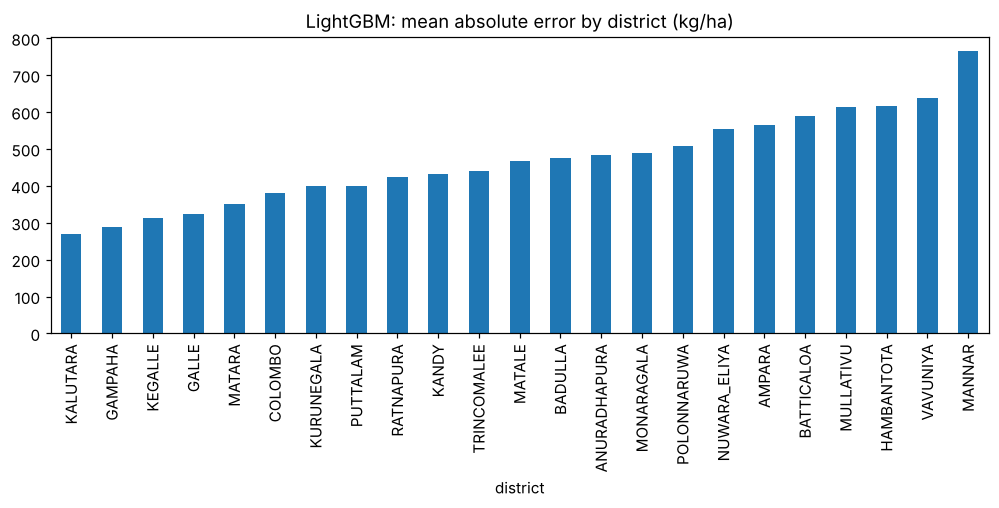

In [11]:
best = summary.drop([i for i in summary.index if "Baseline" in i]).index[0]
e = t.assign(abs_err=(t["target"] - t[best]).abs())
print("Best model:", best)
display(e.groupby(["year", "season"])["abs_err"].mean().round(0).unstack())
by_d = e.groupby("district")["abs_err"].mean().sort_values()
by_d.plot.bar(figsize=(11, 3.5), title=f"{best}: mean absolute error by district (kg/ha)"); plt.show()

### 5.3 Feature importance (tree ensembles)

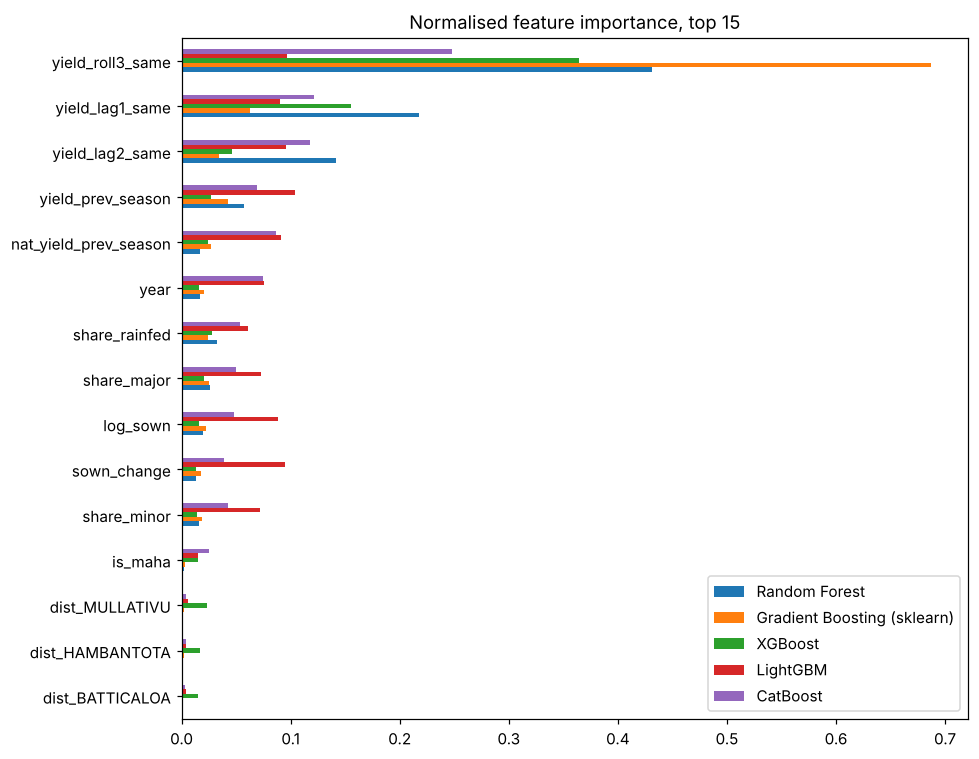

In [12]:
imp = res["importances"].copy()
imp["mean"] = imp.mean(axis=1)
top = imp.sort_values("mean").tail(15).drop(columns="mean")
top.plot.barh(figsize=(9, 7), title="Normalised feature importance, top 15"); plt.tight_layout(); plt.show()

## 6. Is the ranking stable?
### 6.1 Different train/test split years

In [13]:
rows = {}
for end in [2011, 2014, 2017, 2020]:
    r = pm.run_experiment(X, train_end=end)
    rows[f"train<= {end}"] = r["table"]["RMSE (kg/ha)"]
by_split = pd.DataFrame(rows)
display(by_split.round(1))
print("Best model per split:"); print(by_split.drop([i for i in by_split.index if "Baseline" in i]).idxmin())
print("\nAverage rank across splits (1 = best):")
print(by_split.rank().mean(axis=1).sort_values().round(2))

,train<= 2011,train<= 2014,train<= 2017,train<= 2020
model,,,,
Baseline: same season last year,677.2,699.6,774.1,859.0
Baseline: 3-year average,636.4,670.3,745.9,833.7
Bagging (decision trees),603.1,626.1,671.4,775.2
Random Forest,593.5,602.8,661.5,758.6
Gradient Boosting (sklearn),605.0,605.4,645.9,759.4
XGBoost,605.9,596.0,643.6,730.3
LightGBM,585.5,591.2,633.0,741.4
CatBoost,585.5,575.6,636.5,730.9
ANN (MLP),617.1,610.4,652.8,746.0


Best model per split:
train<= 2011    Stacking (RF + Boosting + ANN -> Ridge)
train<= 2014                                   CatBoost
train<= 2017                                   LightGBM
train<= 2020                                    XGBoost
dtype: str

Average rank across splits (1 = best):
model
CatBoost                                    2.25
Stacking (RF + Boosting + ANN -> Ridge)     2.25
LightGBM                                    2.75
XGBoost                                     4.25
Hybrid (RF + ANN residual)                  5.00
Random Forest                               6.50
Gradient Boosting (sklearn)                 6.75
ANN (MLP)                                   7.00
Bagging (decision trees)                    8.25
Baseline: 3-year average                   10.00
Baseline: same season last year            11.00
dtype: float64


### 6.2 Different random seeds (Random Forest vs LightGBM)

In [14]:
import lightgbm, sklearn.ensemble as ske
seed_rows = {}
feats = pm.feature_columns(X); tr = X["year"] <= TRAIN_END
Xtr, Xte = pm._lag_filled(X.loc[tr, feats]), pm._lag_filled(X.loc[~tr, feats])
ytr, yte = X.loc[tr, "target"], X.loc[~tr, "target"]
for s in range(5):
    rf = ske.RandomForestRegressor(400, max_depth=12, min_samples_leaf=3, max_features=0.5, n_jobs=-1, random_state=s).fit(Xtr, ytr)
    lg = lightgbm.LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=15, subsample=0.8, subsample_freq=1,
                                colsample_bytree=0.8, min_child_samples=10, random_state=s, verbose=-1).fit(Xtr, ytr)
    seed_rows[f"seed {s}"] = {"Random Forest": np.sqrt(np.mean((yte - rf.predict(Xte)) ** 2)),
                              "LightGBM": np.sqrt(np.mean((yte - lg.predict(Xte)) ** 2))}
by_seed = pd.DataFrame(seed_rows)
by_seed["mean"], by_seed["std"] = by_seed.mean(axis=1), by_seed.std(axis=1)
display(by_seed.round(1))

,seed 0,seed 1,seed 2,seed 3,seed 4,mean,std
Random Forest,662.5,661.5,660.3,664.8,662.3,662.3,1.7
LightGBM,638.4,642.6,640.9,635.4,639.8,639.4,2.7


## 7. Experiment: does knowing the harvested area help?
`harvest_ratio = harvested / sown` captures crop failure (drought, flood, pests), but it is only known at harvest. Adding it turns the model into an early-warning *estimate* rather than a forecast.

In [15]:
Xh = pm.make_features(df, use_harvest_ratio=True)
rh = pm.run_experiment(Xh, train_end=TRAIN_END, use=["Random Forest", "LightGBM", "Stacking"], include_hybrid=False)
cmp = pd.DataFrame({"forecast features": table["RMSE (kg/ha)"], "+ harvest ratio": rh["table"]["RMSE (kg/ha)"]}).dropna()
display(cmp.round(1))

,forecast features,+ harvest ratio
model,,
Baseline: 3-year average,745.9,745.9
Baseline: same season last year,774.1,774.1
LightGBM,633.0,653.1
Random Forest,661.5,665.7
Stacking (RF + Boosting + ANN -> Ridge),640.2,640.2


## 8. Economic view: what is a season's harvest worth?

In [ ]:
price = pd.read_csv("samba_paddy_price.csv", comment="#"); price["date"] = pd.to_datetime(price["period"])
p = price.set_index("date")["value"]
def season_price(y, s):   # harvest months: Yala y -> Aug-Oct y, Maha y (y/y+1) -> Feb-Apr y+1
    m = pd.date_range(f"{y}-08-01" if s == "Yala" else f"{y+1}-02-01", periods=3, freq="MS")
    return p.reindex(m).mean()
prod = df.groupby(["year", "season"])["production_mt"].sum().reset_index()
prod["samba_rs_kg"] = [season_price(y, s) for y, s in zip(prod["year"], prod["season"])]
prod = prod.dropna(); prod["value_rs_bn"] = prod["production_mt"] * 1000 * prod["samba_rs_kg"] / 1e9
display(prod.round(1))
rmse_best = table.loc[best, "RMSE (kg/ha)"]; base_err = table.loc["Baseline: same season last year", "RMSE (kg/ha)"]
area = df[df["year"] == df["year"].max()]["harvested_ha"].sum() / 2
print(f"A {base_err - rmse_best:.0f} kg/ha smaller error, over ~{area:,.0f} ha per season at Rs {p.iloc[-12:].mean():.0f}/kg, "
      f"is about Rs {(base_err - rmse_best) * area * p.iloc[-12:].mean() / 1e9:.1f} bn of better-estimated harvest value per season.")

## 9. Interpretation and conclusion

**Results (test seasons 2018-2025, 368 district-seasons)**

| | Best model | RMSE (kg/ha) | vs naive |
|---|---|---|---|
| Baseline | 3-year average | 746 | +3.6% |
| Bagging | Random Forest | 661 | +14.6% |
| Boosting | LightGBM | **633** | **+18.2%** |
| Stacking | RF + LightGBM + ANN + Ridge | 640 (488 excl. crisis, the best) | +17.3% |
| Hybrid | RF + ANN residual | 656 | +15.3% |

**1. Every ensemble beats the farmer's rule of thumb.** Guessing "same as last year" misses by 774 kg/ha. The best models cut that to about 633 kg/ha (MAPE ≈ 12.8%, R² ≈ 0.55). That is a real but moderate gain: yields depend a lot on rainfall, which is not in this dataset.

**2. Why boosting beat bagging.** Bagging (bagged trees, Random Forest) trains deep trees independently and averages them, which mainly reduces *variance*. Here the signal is mostly a persistent district level plus small adjustments for season, irrigation mix and recent shocks, so the main problem is *bias*. Boosting fits each new shallow tree to the errors that remain, so it captures these small, additive corrections. Averaging also pulls Random Forest predictions towards the training mean, which hurts in 2018-2019, when record yields sat at the top of the historical range. The seed test shows the gap is real: RF 662 ± 2 vs LightGBM 639 ± 3 kg/ha.

**3. Stacking is the most reliable choice.** Across four different split years, Stacking and CatBoost share the best average rank (2.25). Stacking also wins outright for train ≤ 2011, and it has the lowest error once the crisis seasons are removed (488 kg/ha). The Ridge meta-learner combines models that make *different* mistakes: trees capture district thresholds, while the ANN gives a smooth, near-linear response to past yields. When errors are less correlated, combining models helps. The top boosters and Stacking are within about 10 kg/ha of each other and swap places between splits, so it is fairer to call them comparable.

**4. The hybrid improves its parent model.** The RF + ANN residual hybrid lowers Random Forest's error from 661 to 656 kg/ha (from 513 to 504 excluding the crisis). The ANN learns part of the systematic error left by the forest's averaging. It does not reach boosting, because one correction step is weaker than hundreds of boosting rounds.

**5. The 2021 fertiliser ban is the big lesson.** For Maha 2021/22 the best model's error jumps to about 1,340 kg/ha, against 250-600 kg/ha in normal seasons, and Yala 2022 is also poor (about 740 kg/ha). The national yield fell 37% because of a policy decision. Nothing in the 40 years of history signalled it, so no model, however advanced, could predict it. Ensembles learn *normal* agronomy. To capture shocks they need inputs such as fertiliser availability, rainfall and prices.

**6. What drives yield?** The 3-year average of the same season (about 37% of importance), last year's yield and the previous season dominate. Yield is persistent because soil, water access and farming practice change slowly. Irrigation mix, sown area and the national yield of the previous season add the rest.

**7. Districts and seasons (economic story).** Dry-zone districts with major irrigation (Hambantota ≈ 5,600 kg/ha, Polonnaruwa ≈ 5,000, Ampara, Anuradhapura) are the most productive. The wet-zone districts (Colombo, Galle, Kalutara, Gampaha) and Jaffna yield the least. Yala averages slightly more than Maha (4,017 vs 3,928 kg/ha in 2016-2025) because it is grown mainly where irrigation water is secure. Predictions are most accurate for the stable wet-zone districts (error ≈ 270-380 kg/ha) and least accurate for the northern and eastern districts such as Mannar, Vavuniya, Mullaitivu and Batticaloa (≈ 600-770 kg/ha), where conditions vary more. Jaffna and Kilinochchi have too many gaps in recent lags to be in the test set.

**8. Harvest ratio did not help.** Adding harvested/sown area did not improve accuracy (LightGBM 633 → 653, Stacking unchanged). Yield is already measured per *harvested* hectare, so failed land is removed from the denominator and the ratio adds little new information.

**9. Economic value.** At recent Samba prices (≈ Rs 129/kg), Maha 2025 production is worth about Rs 458 bn at the farm gate. On roughly 650,000 ha per season, a 141 kg/ha smaller forecast error means about Rs 12 bn of harvest value is estimated more accurately each season. That helps the Paddy Marketing Board and the government plan purchases, storage and imports.

**Limitations:** no weather, fertiliser or price features; a single time-ordered split per experiment (checked with four split years); production is derived as yield × harvested area; the Samba price series only starts in 2021.


## 10. Dashboard
`streamlit run app.py` opens an interactive dashboard with five tabs: Overview (yield trends and district ranking), Model comparison (live metrics with hyperparameter sliders), District explorer, What-if predictor, and Rural economy (Samba price and farm-gate value).

---
**AI disclosure:** code generated with the assistance of Claude (Anthropic); reviewed, executed and interpreted by the student.

In [3]:
!streamlit run app.py

'streamlit' is not recognized as an internal or external command,
operable program or batch file.


In [ ]:
!pip install streamlit
!python -m streamlit run app.py